# Heart Disease Risk Prediction: Random Forest
**Health Risk Assessment System** - Machine Learning (23MCAJ301)

This notebook trains and evaluates the **Random Forest** classifier on the Health Risk Predictor dataset. It is self-contained: run all cells from top to bottom in Google Colab.

**Contents**
1. Load the dataset and explore it (Level-1 univariate charts)
2. Define the 3-class target (Low / Medium / High) by quantile binning
3. Bivariate analysis and correlation analysis (identifying data leakage)
4. Pre-processing: leakage removal, one-hot encoding, stratified 80:20 split
5. Random Forest: training, evaluation, confusion matrix, feature importance
6. Predicting the risk for a new person

The pre-processing and the train/test split (`random_state=42`) are identical to the XGBoost notebook, so the two models can be compared fairly.


USING KAGGLE API KEY

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("tanyamishra260/health-risk-predictor-dataset")

print("Path to dataset files:", path)

100%|██████████| 7.61M/7.61M [00:00<00:00, 214MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/tanyamishra260/health-risk-predictor-dataset/versions/1


# LOAD THE DATSET AND READ THE **DATAFRAME**
 We load the CSV file and take a look at the first few rows. This is always the very first step to be followed.


In [ ]:
import os
import pandas as pd
csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]

if csv_files:
    file_path = os.path.join(path, csv_files[0])
    df = pd.read_csv(file_path)
    print(df.head(10))
else:
    print("CSV file not found")

   Age  gender ethnicity education_level  income_level employment_status  \
0   58    Male     Asian      Highschool  Lower-Middle          Employed   
1   52  Female     White      Highschool        Middle          Employed   
2   60    Male  Hispanic      Highschool        Middle        Unemployed   
3   74  Female     Black      Highschool           Low           Retired   
4   46    Male     White        Graduate        Middle           Retired   
5   46  Female     White      Highschool  Upper-Middle          Employed   
6   75  Female     White        Graduate  Upper-Middle           Retired   
7   62    Male     White    Postgraduate        Middle        Unemployed   
8   37    Male     Black      Highschool  Lower-Middle          Employed   
9   59  Female     White        Graduate        Middle          Employed   

  smoking_status  alcohol_consumption_per_week  \
0          Never                             0   
1         Former                             1   
2          Ne

# **Information On DataSet**
*DataFrame Details specifies number of columns(33), Datatype of each columns Int, float & Object *


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 97297 entries, 0 to 97296
Data columns (total 33 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Age                                 97297 non-null  int64  
 1   gender                              97297 non-null  object 
 2   ethnicity                           97297 non-null  object 
 3   education_level                     97297 non-null  object 
 4   income_level                        97297 non-null  object 
 5   employment_status                   97297 non-null  object 
 6   smoking_status                      97297 non-null  object 
 7   alcohol_consumption_per_week        97297 non-null  int64  
 8   physical_activity_minutes_per_week  97297 non-null  int64  
 9   diet_score                          97297 non-null  float64
 10  sleep_hours_per_day                 97297 non-null  float64
 11  screen_time_hours_per_day           97297

# **Summary About Data**
*Summary of data related to count, mean, standard deviation, minimum and maximum value, percentile*

In [ ]:
df.describe()

,Age,alcohol_consumption_per_week,physical_activity_minutes_per_week,diet_score,sleep_hours_per_day,screen_time_hours_per_day,family_history_diabetes,hypertension_history,cardiovascular_history,bmi,...,triglycerides,glucose_fasting,glucose_postprandial,insulin_level,hba1c,diabetes_risk_score,hypertension_risk_score,heart_disease_risk_score,obesity_risk_score,cholesterol_risk_score
count,97297.000000,97297.000000,97297.000000,97297.000000,97297.000000,97297.000000,97297.000000,97297.000000,97297.000000,97297.000000,...,97297.000000,97297.000000,97297.000000,97297.000000,97297.000000,97297.000000,97297.000000,97297.000000,97297.000000,97297.000000
mean,50.192699,2.004543,118.942886,5.995214,6.997708,5.997031,0.219657,0.250912,0.079067,25.615093,...,121.466407,111.121792,160.014348,9.063591,6.520338,41.237414,41.137170,32.063255,48.407241,26.075076
std,15.492557,1.418060,84.441920,1.780096,1.093726,2.469805,0.414017,0.433540,0.269845,3.588387,...,43.393422,13.590382,30.938915,4.956342,0.813710,10.990720,12.755572,15.412755,10.998884,13.028452
min,19.000000,0.000000,0.000000,0.000000,3.000000,0.500000,0.000000,0.000000,0.000000,15.000000,...,30.000000,60.000000,70.000000,2.000000,4.000000,1.821211,0.000000,0.000000,12.711686,0.000000
25%,38.000000,1.000000,57.000000,4.800000,6.300000,4.300000,0.000000,0.000000,0.000000,23.200000,...,91.000000,102.000000,139.000000,5.090000,5.970000,33.611350,32.136805,20.389335,40.898793,16.506114
50%,51.000000,2.000000,100.000000,6.000000,7.000000,6.000000,0.000000,0.000000,0.000000,25.600000,...,121.000000,111.000000,160.000000,8.790000,6.520000,40.773364,40.941950,30.793098,48.509658,25.497612
75%,61.000000,3.000000,160.000000,7.200000,7.700000,7.700000,0.000000,1.000000,0.000000,28.000000,...,151.000000,120.000000,181.000000,12.450000,7.070000,48.430041,49.911238,42.564698,55.928994,34.804830
max,90.000000,10.000000,833.000000,10.000000,10.000000,16.800000,1.000000,1.000000,1.000000,39.200000,...,344.000000,172.000000,287.000000,32.220000,9.800000,84.329497,92.102337,97.902483,86.832124,83.112231


In [ ]:
df.shape

(97297, 33)

In [ ]:
df.isnull().sum()

,0
Age,0
gender,0
ethnicity,0
education_level,0
income_level,0
employment_status,0
smoking_status,0
alcohol_consumption_per_week,0
physical_activity_minutes_per_week,0
diet_score,0


In [ ]:
df.dtypes

,0
Age,int64
gender,object
ethnicity,object
education_level,object
income_level,object
employment_status,object
smoking_status,object
alcohol_consumption_per_week,int64
physical_activity_minutes_per_week,int64
diet_score,float64


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

# **LEVEL-1**
*Data charts specifies the count, skweness and other features.*
*Age, Gender, Ethincity, Education, Income*

**Distribution of Age**

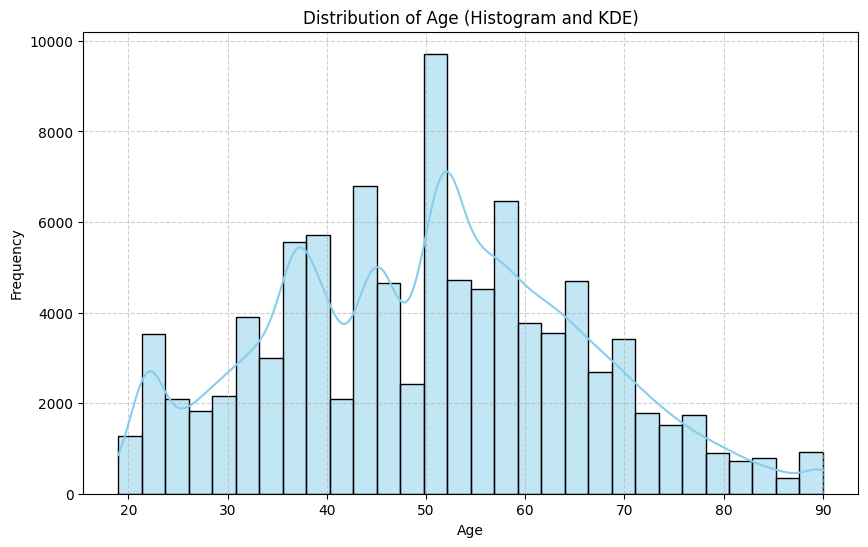

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(df['Age'], kde=True, color='skyblue', bins=30)
plt.title('Distribution of Age (Histogram and KDE)')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Distribution of Gender**

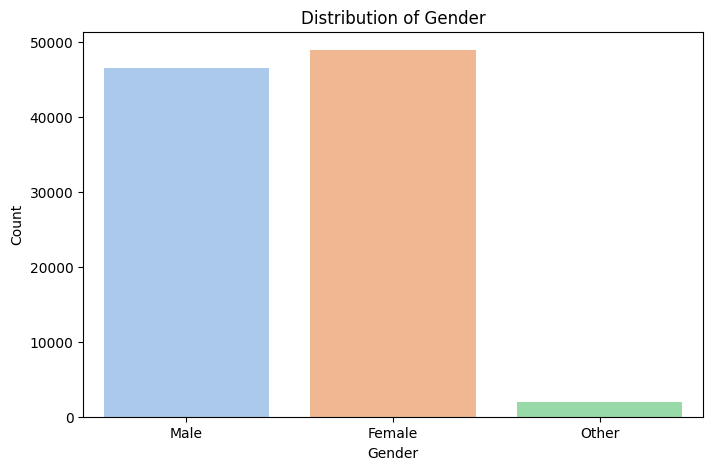

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='gender', palette='pastel')
plt.title('Distribution of Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

**Distribution of Ethnicity**

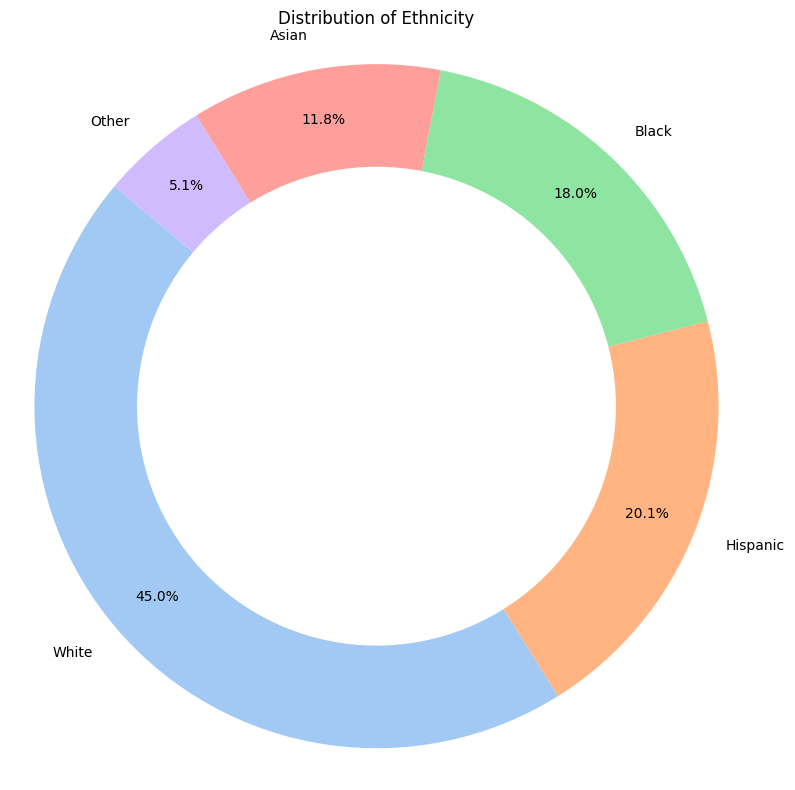

In [ ]:
# Prepare data for donut chart
ethnicity_counts = df['ethnicity'].value_counts()

# Plotting
plt.figure(figsize=(8, 8))
plt.pie(ethnicity_counts, labels=ethnicity_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'), pctdistance=0.85)

# Draw a white circle at the center to make it a donut
centre_circle = plt.Circle((0,0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title('Distribution of Ethnicity')
plt.axis('equal')
plt.tight_layout()
plt.show()

**Distribution of Education Level**

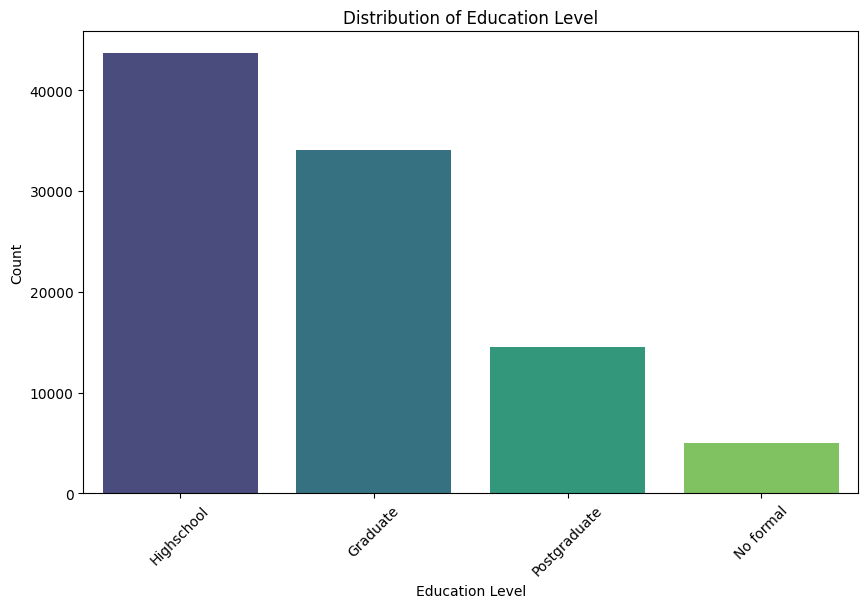

In [ ]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='education_level', palette='viridis', order=df['education_level'].value_counts().index)
plt.title('Distribution of Education Level')
plt.xlabel('Education Level')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

**Distribution of Income Level**

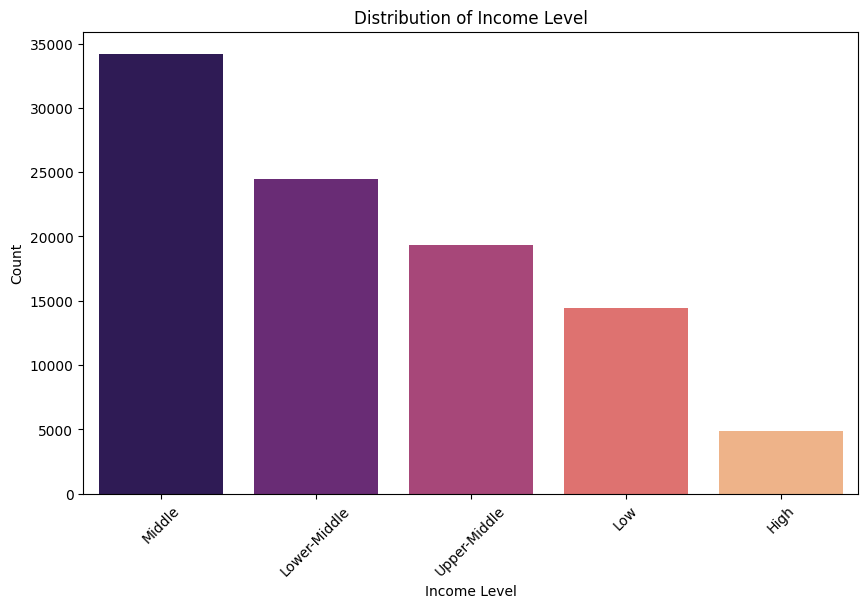

In [ ]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='income_level', palette='magma', order=df['income_level'].value_counts().index)
plt.title('Distribution of Income Level')
plt.xlabel('Income Level')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

 **Distribution of Smoking Status**

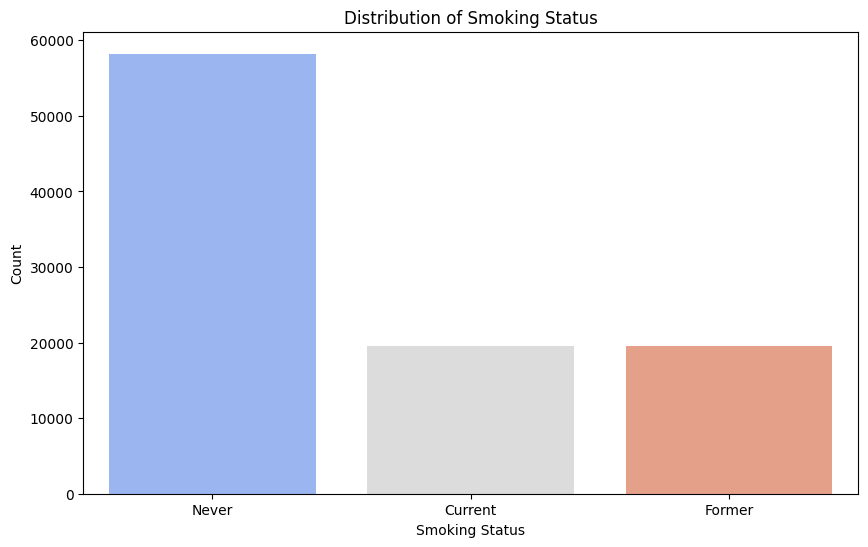

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='smoking_status', palette='coolwarm', order=df['smoking_status'].value_counts().index)
plt.title('Distribution of Smoking Status')
plt.xlabel('Smoking Status')
plt.ylabel('Count')
plt.show()

### **Distribution of Sleep Hours**

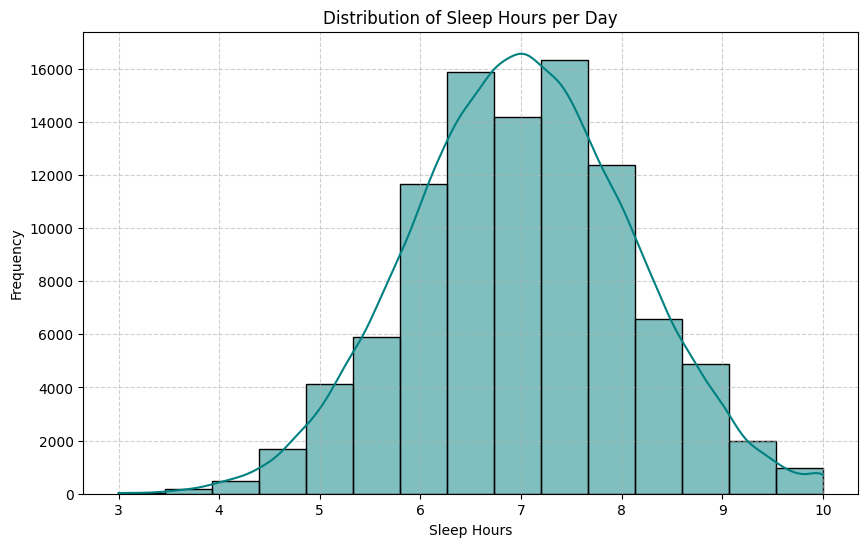

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(df['sleep_hours_per_day'], kde=True, color='teal', bins=15)
plt.title('Distribution of Sleep Hours per Day')
plt.xlabel('Sleep Hours')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Distribution of Employment Status**

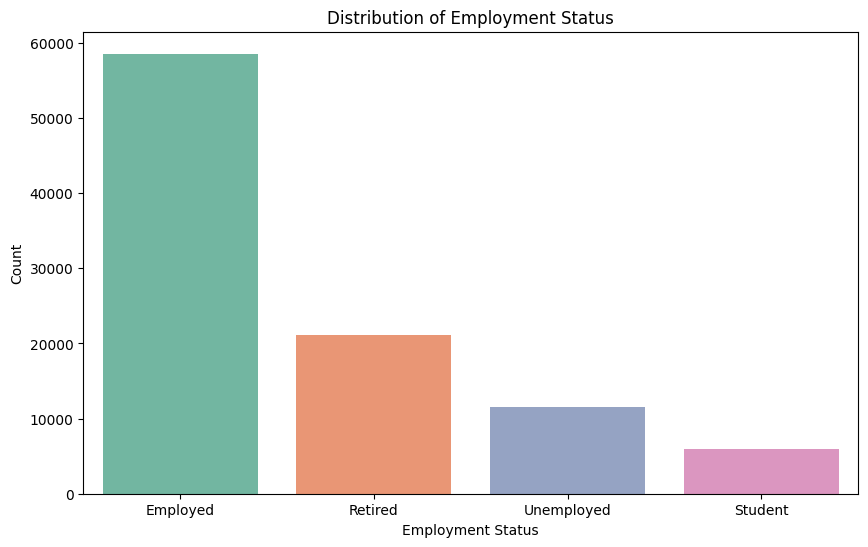

In [ ]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='employment_status', palette='Set2', order=df['employment_status'].value_counts().index)
plt.title('Distribution of Employment Status')
plt.xlabel('Employment Status')
plt.ylabel('Count')
plt.show()

### **Distribution of BMI**
We will visualize the distribution of Body Mass Index (BMI) using a histogram and Kernel Density Estimate (KDE) to understand the weight distribution of the participants.

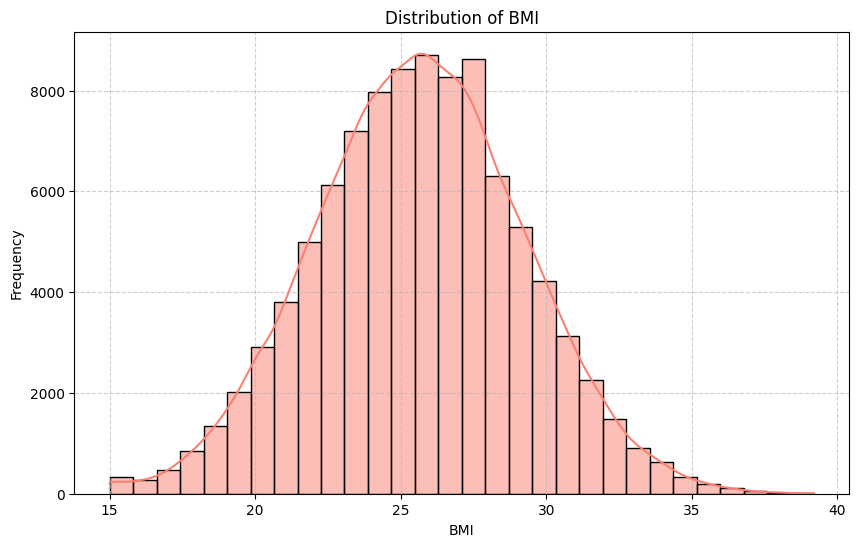

Mean BMI: 25.62
Median BMI: 25.60


In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(df['bmi'], kde=True, color='salmon', bins=30)
plt.title('Distribution of BMI')
plt.xlabel('BMI')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Quick stats for BMI
print(f"Mean BMI: {df['bmi'].mean():.2f}")
print(f"Median BMI: {df['bmi'].median():.2f}")

### **Distribution of Alcohol Consumption**
We will visualize the number of alcohol units consumed per week using a histogram to understand the drinking habits in this dataset.

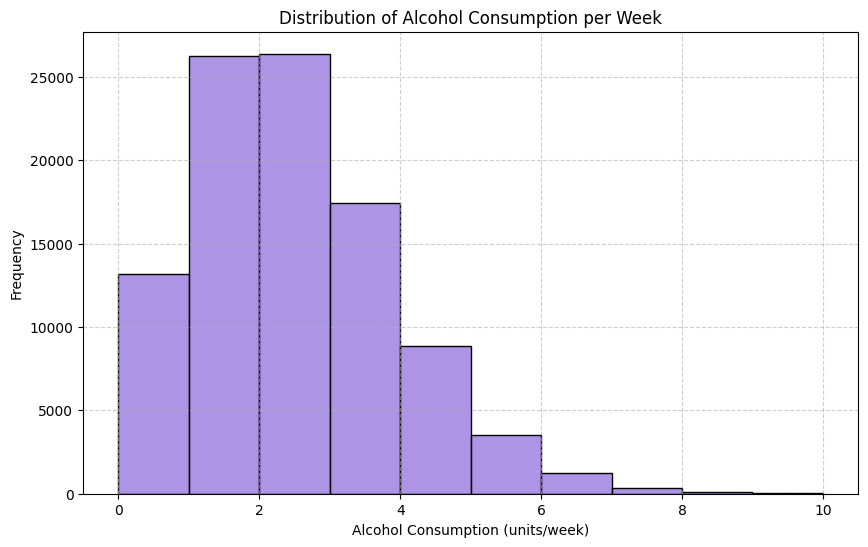

alcohol_consumption_per_week
0     13159
1     26254
2     26389
3     17410
4      8885
5      3522
6      1235
7       347
8        81
9        13
10        2
Name: count, dtype: int64


In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(df['alcohol_consumption_per_week'], bins=10, color='mediumpurple', kde=False)
plt.title('Distribution of Alcohol Consumption per Week')
plt.xlabel('Alcohol Consumption (units/week)')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Summary stats
print(df['alcohol_consumption_per_week'].value_counts().sort_index())

### **Distribution of Physical Activity**
We will visualize the weekly physical activity in minutes to understand how active the participants are.

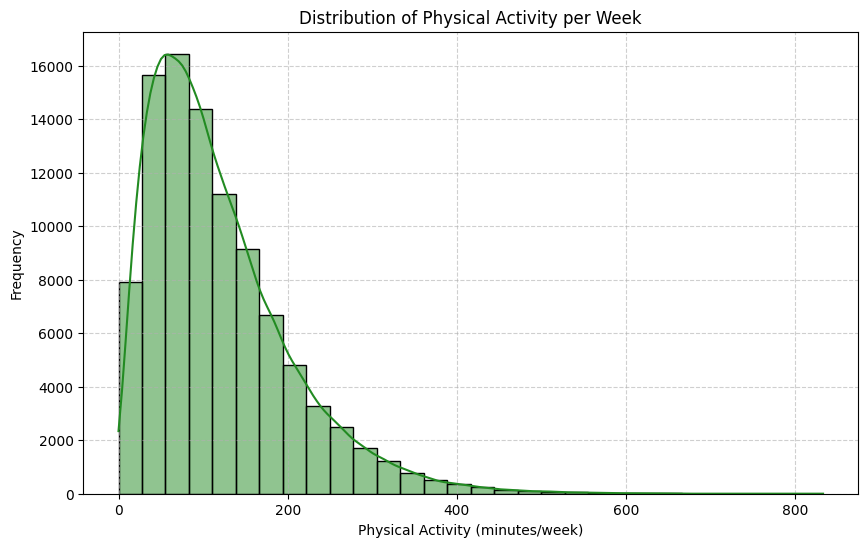

Mean Activity: 118.94 mins
Median Activity: 100.00 mins


In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(df['physical_activity_minutes_per_week'], kde=True, color='forestgreen', bins=30)
plt.title('Distribution of Physical Activity per Week')
plt.xlabel('Physical Activity (minutes/week)')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Summary stats for Physical Activity
print(f"Mean Activity: {df['physical_activity_minutes_per_week'].mean():.2f} mins")
print(f"Median Activity: {df['physical_activity_minutes_per_week'].median():.2f} mins")

### **Distribution of Diet Score**
We will visualize the diet score distribution using a histogram and KDE to understand the nutritional patterns in the dataset.

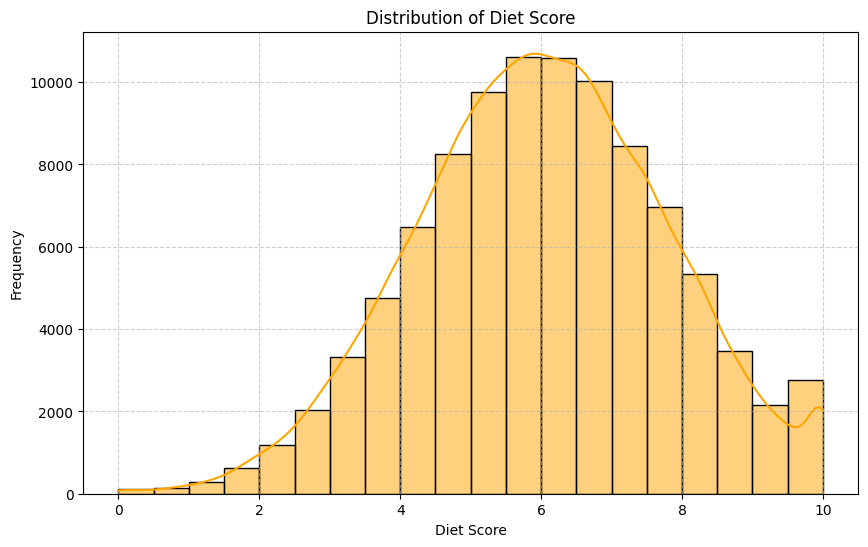

Mean Diet Score: 6.00
Median Diet Score: 6.00


In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(df['diet_score'], kde=True, color='orange', bins=20)
plt.title('Distribution of Diet Score')
plt.xlabel('Diet Score')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Quick stats for Diet Score
print(f"Mean Diet Score: {df['diet_score'].mean():.2f}")
print(f"Median Diet Score: {df['diet_score'].median():.2f}")

### **Distribution of Blood Pressure (Systolic & Diastolic)**
We will visualize the distribution of systolic and diastolic blood pressure levels to identify common ranges and potential outliers in cardiovascular health.

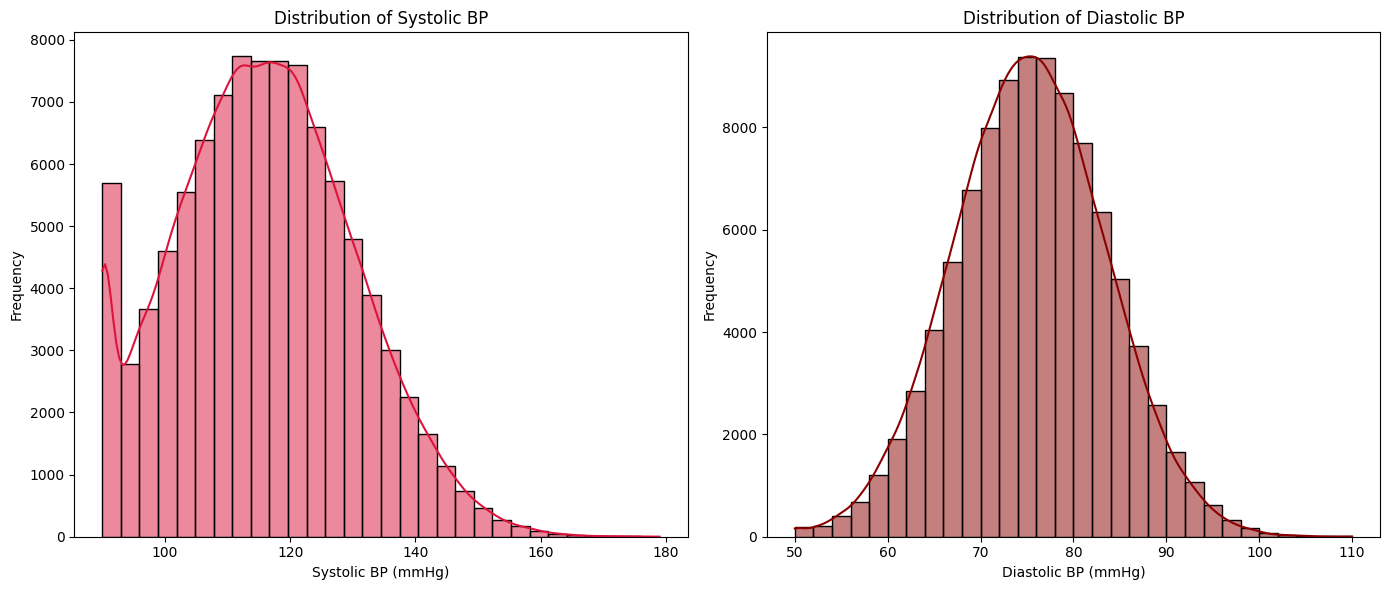

Mean Systolic BP: 115.80
Mean Diastolic BP: 75.23


In [ ]:
plt.figure(figsize=(14, 6))

# Systolic BP
plt.subplot(1, 2, 1)
sns.histplot(df['systolic_bp'], kde=True, color='crimson', bins=30)
plt.title('Distribution of Systolic BP')
plt.xlabel('Systolic BP (mmHg)')
plt.ylabel('Frequency')

# Diastolic BP
plt.subplot(1, 2, 2)
sns.histplot(df['diastolic_bp'], kde=True, color='darkred', bins=30)
plt.title('Distribution of Diastolic BP')
plt.xlabel('Diastolic BP (mmHg)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

# Summary stats
print(f"Mean Systolic BP: {df['systolic_bp'].mean():.2f}")
print(f"Mean Diastolic BP: {df['diastolic_bp'].mean():.2f}")

### **Distribution of Heart Rate and Fasting Glucose**
We continue the univariate analysis of health indicators by looking at heart rate and fasting glucose levels.

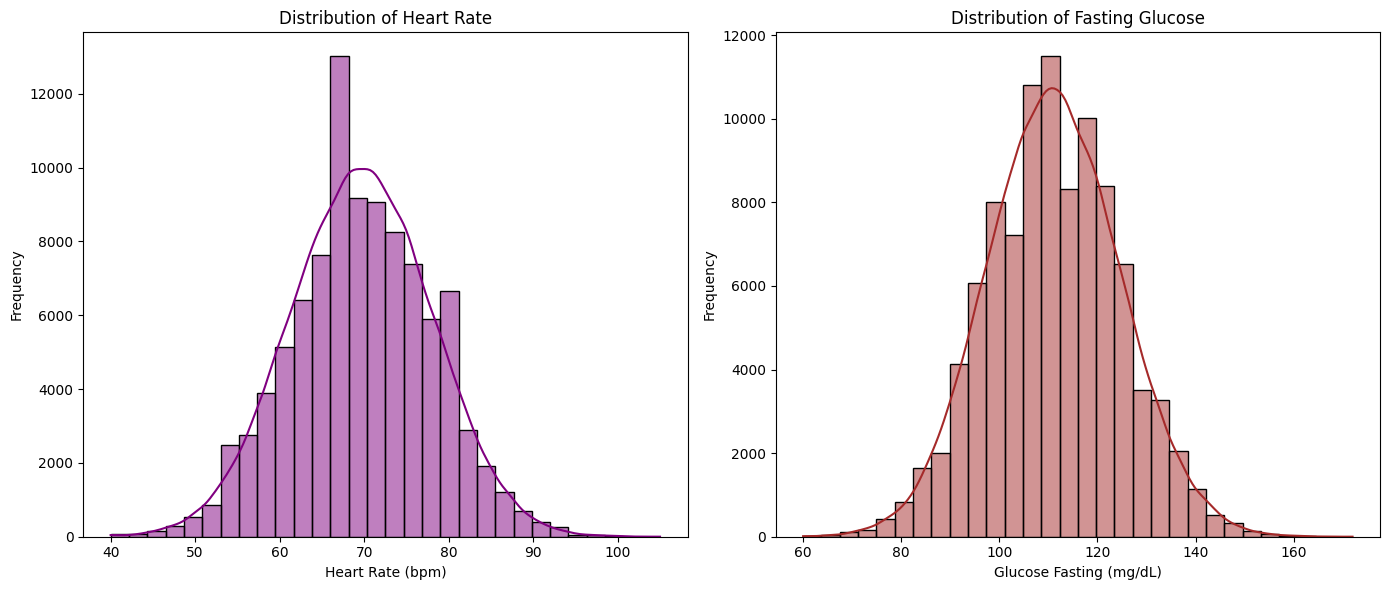

Mean Heart Rate: 69.63 bpm
Mean Fasting Glucose: 111.12 mg/dL


In [ ]:
plt.figure(figsize=(14, 6))

# Heart Rate
plt.subplot(1, 2, 1)
sns.histplot(df['heart_rate'], kde=True, color='purple', bins=30)
plt.title('Distribution of Heart Rate')
plt.xlabel('Heart Rate (bpm)')
plt.ylabel('Frequency')

# Glucose Fasting
plt.subplot(1, 2, 2)
sns.histplot(df['glucose_fasting'], kde=True, color='brown', bins=30)
plt.title('Distribution of Fasting Glucose')
plt.xlabel('Glucose Fasting (mg/dL)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

# Summary stats
print(f"Mean Heart Rate: {df['heart_rate'].mean():.2f} bpm")
print(f"Mean Fasting Glucose: {df['glucose_fasting'].mean():.2f} mg/dL")

## **Step 2: Target Variable Definition**
We will now bin the continuous `heart_disease_risk_score` into categorical groups ('Low', 'Medium', 'High') to facilitate classification analysis and bivariate visualization.

Distribution of Heart Disease Risk Groups:
heart_disease_risk_group
High      32433
Low       32432
Medium    32432
Name: count, dtype: int64


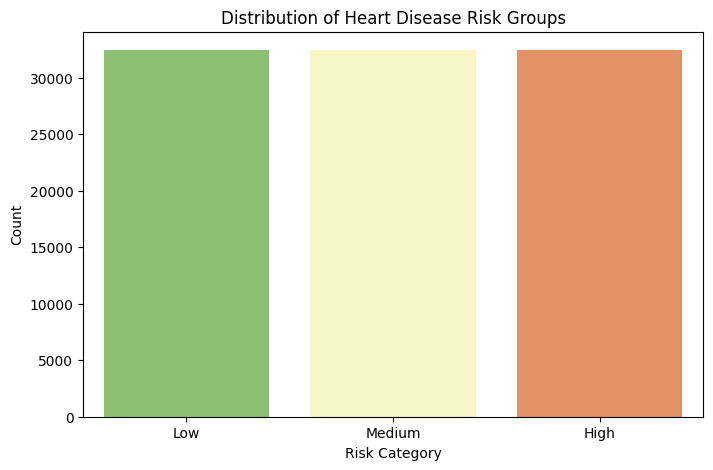

In [ ]:
# Binning the target variable into 3 categories using quantiles
df['heart_disease_risk_group'] = pd.qcut(df['heart_disease_risk_score'], q=3, labels=['Low', 'Medium', 'High'])

# Display the distribution of the new categories
risk_counts = df['heart_disease_risk_group'].value_counts()
print("Distribution of Heart Disease Risk Groups:")
print(risk_counts)

# Visualize the distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='heart_disease_risk_group', palette='RdYlGn_r', order=['Low', 'Medium', 'High'])
plt.title('Distribution of Heart Disease Risk Groups')
plt.xlabel('Risk Category')
plt.ylabel('Count')
plt.show()

## **Step 3: Bivariate Analysis**
We will explore the relationship between our features and the `heart_disease_risk_group` to identify potential predictors.

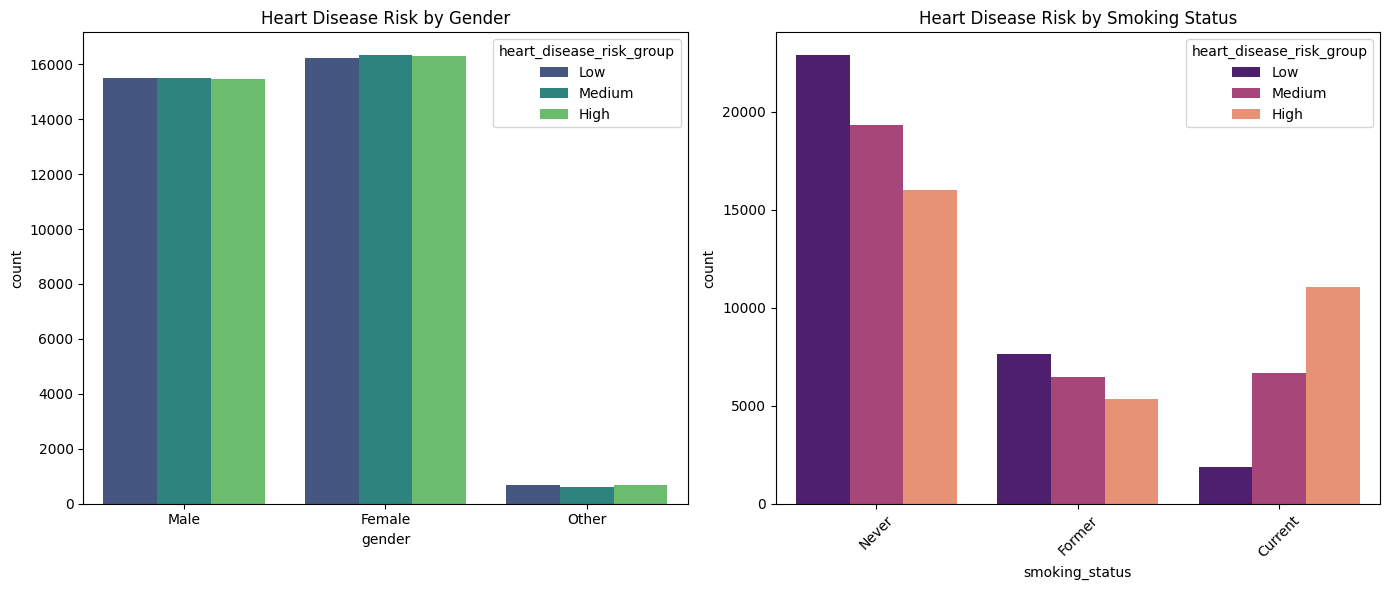

In [ ]:
plt.figure(figsize=(14, 6))

# Gender vs Risk Group
plt.subplot(1, 2, 1)
sns.countplot(data=df, x='gender', hue='heart_disease_risk_group', palette='viridis')
plt.title('Heart Disease Risk by Gender')

# Smoking Status vs Risk Group
plt.subplot(1, 2, 2)
sns.countplot(data=df, x='smoking_status', hue='heart_disease_risk_group', palette='magma')
plt.title('Heart Disease Risk by Smoking Status')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

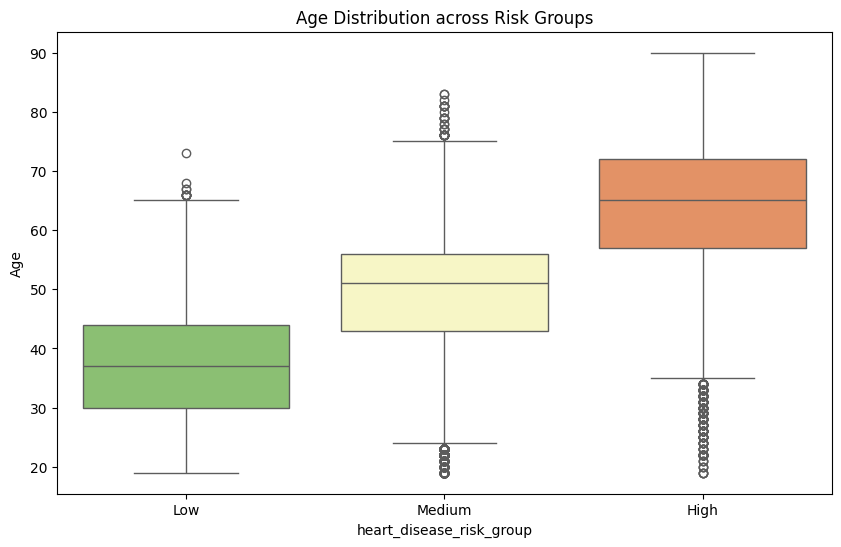

In [ ]:
# Age vs Risk Group Boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='heart_disease_risk_group', y='Age', palette='RdYlGn_r', order=['Low', 'Medium', 'High'])
plt.title('Age Distribution across Risk Groups')
plt.show()

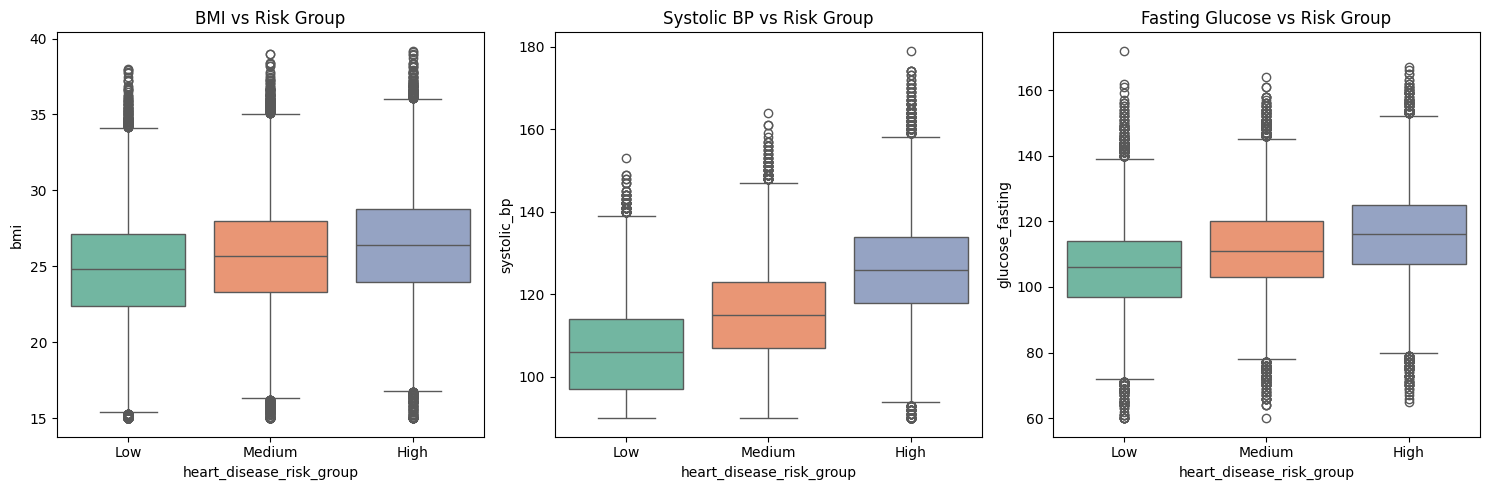

In [ ]:
plt.figure(figsize=(15, 5))

# BMI vs Risk Group
plt.subplot(1, 3, 1)
sns.boxplot(data=df, x='heart_disease_risk_group', y='bmi', palette='Set2', order=['Low', 'Medium', 'High'])
plt.title('BMI vs Risk Group')

# Systolic BP vs Risk Group
plt.subplot(1, 3, 2)
sns.boxplot(data=df, x='heart_disease_risk_group', y='systolic_bp', palette='Set2', order=['Low', 'Medium', 'High'])
plt.title('Systolic BP vs Risk Group')

# Glucose vs Risk Group
plt.subplot(1, 3, 3)
sns.boxplot(data=df, x='heart_disease_risk_group', y='glucose_fasting', palette='Set2', order=['Low', 'Medium', 'High'])
plt.title('Fasting Glucose vs Risk Group')

plt.tight_layout()
plt.show()

## **Step 4: Correlation Analysis**
We will examine the correlations between numerical features to identify highly correlated variables and ensure there is no data leakage from other calculated risk scores.

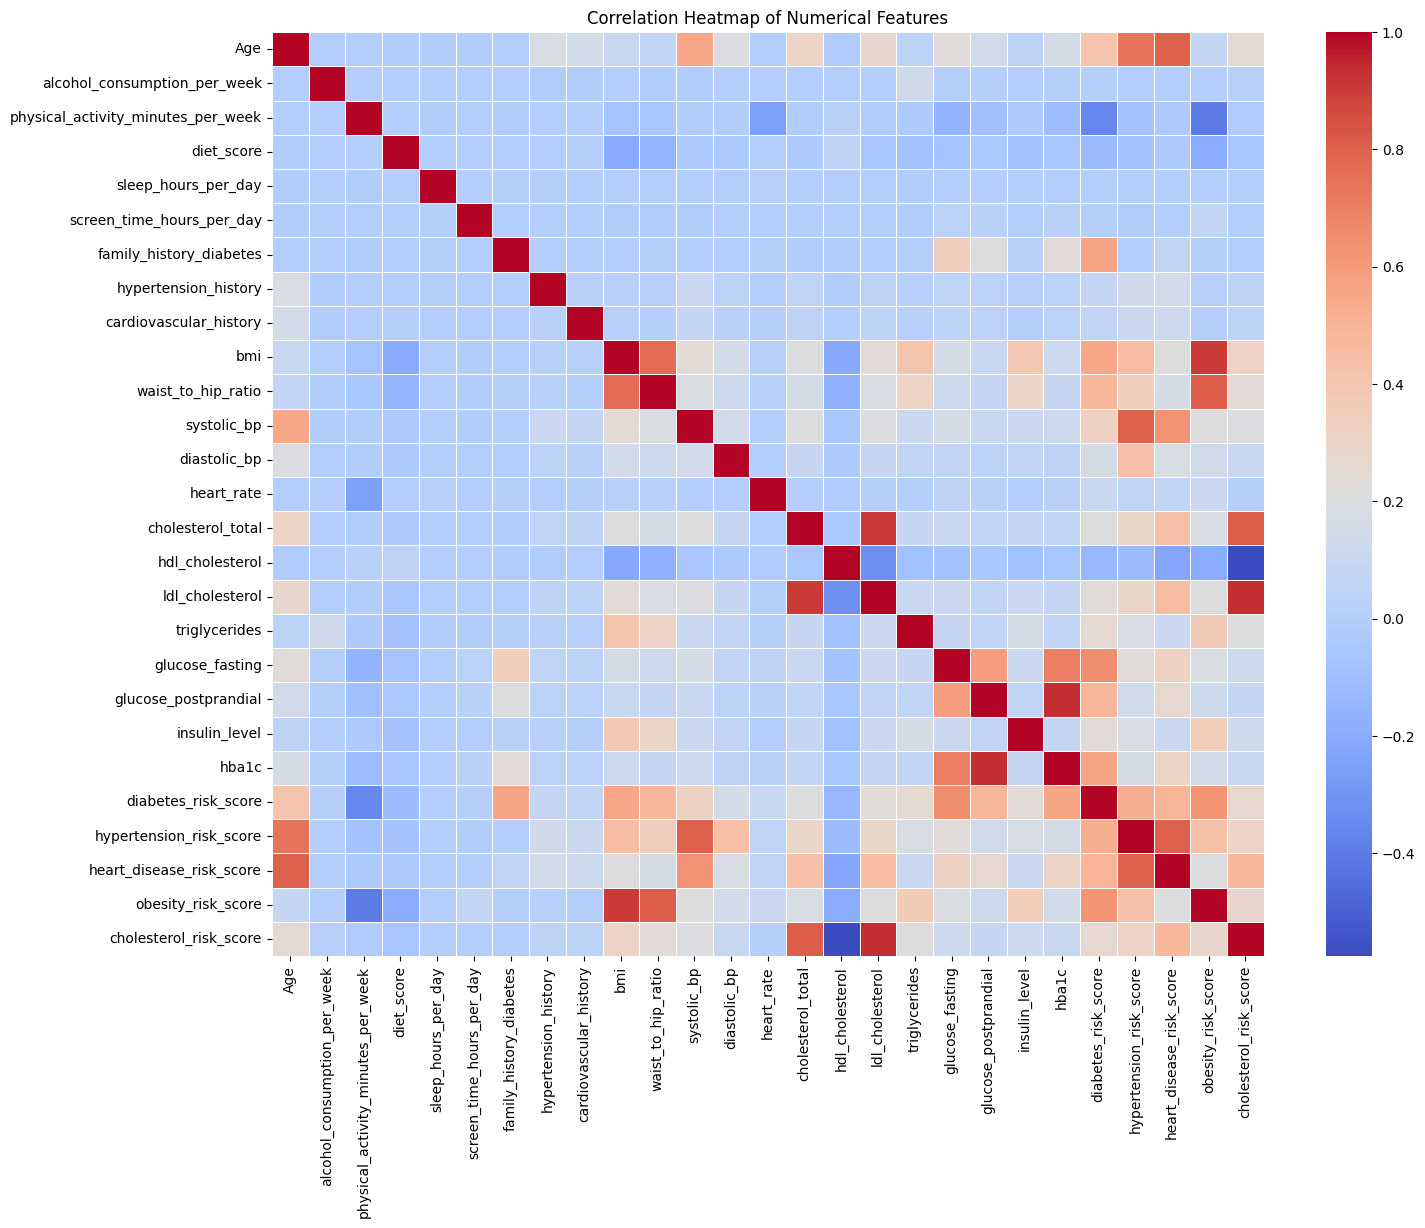

Top correlations with Heart Disease Risk Score:
heart_disease_risk_score    1.000000
hypertension_risk_score     0.799018
Age                         0.798682
systolic_bp                 0.633569
diabetes_risk_score         0.492923
cholesterol_risk_score      0.471368
ldl_cholesterol             0.450703
cholesterol_total           0.430790
glucose_fasting             0.328287
hba1c                       0.304846
Name: heart_disease_risk_score, dtype: float64


In [ ]:
# Select numerical columns for correlation
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Compute correlation matrix
corr_matrix = df[numerical_cols].corr()

# Plot Heatmap
plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

# Specifically check correlation with the target score
print("Top correlations with Heart Disease Risk Score:")
print(corr_matrix['heart_disease_risk_score'].sort_values(ascending=False).head(10))

## **Step 5: Pre-processing & Feature Selection**
Based on the correlation heatmap, we will drop columns that represent data leakage (other risk scores) and the original target variable, then perform one-hot encoding for categorical features.

In [ ]:
# 1. Identify and drop leakage/target columns
# We drop the continuous score and other predicted scores
leakage_cols = [
    'heart_disease_risk_score',
    'hypertension_risk_score',
    'diabetes_risk_score',
    'obesity_risk_score',
    'cholesterol_risk_score'
]

X = df.drop(columns=leakage_cols + ['heart_disease_risk_group'])
y = df['heart_disease_risk_group']

# 2. One-hot encode categorical variables
X_encoded = pd.get_dummies(X, drop_first=True)

# 3. Split the data
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42, stratify=y)

print(f"Original features: {X.shape[1]}")
print(f"Features after encoding: {X_encoded.shape[1]}")
print(f"Training set size: {X_train.shape[0]}")
print(f"Test set size: {X_test.shape[0]}")

Original features: 28
Features after encoding: 40
Training set size: 77837
Test set size: 19460


## **Step 6: Modeling and Evaluation**
We will now train a Random Forest Classifier and evaluate its ability to predict the `heart_disease_risk_group`.

Model Accuracy: 0.8354

Classification Report:
              precision    recall  f1-score   support

        High       0.90      0.87      0.88      6487
         Low       0.87      0.86      0.87      6487
      Medium       0.74      0.77      0.76      6486

    accuracy                           0.84     19460
   macro avg       0.84      0.84      0.84     19460
weighted avg       0.84      0.84      0.84     19460



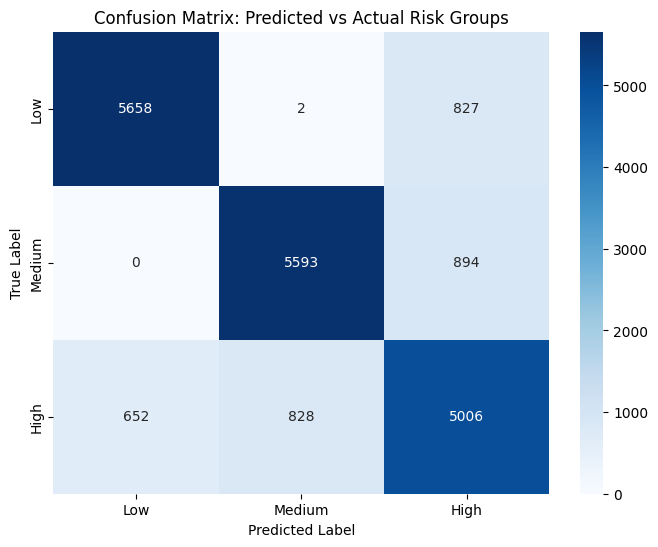

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Initialize and train the Random Forest model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = rf_model.predict(X_test)

# Display overall accuracy
print(f"Model Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Plot the Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Low', 'Medium', 'High'], yticklabels=['Low', 'Medium', 'High'])
plt.title('Confusion Matrix: Predicted vs Actual Risk Groups')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

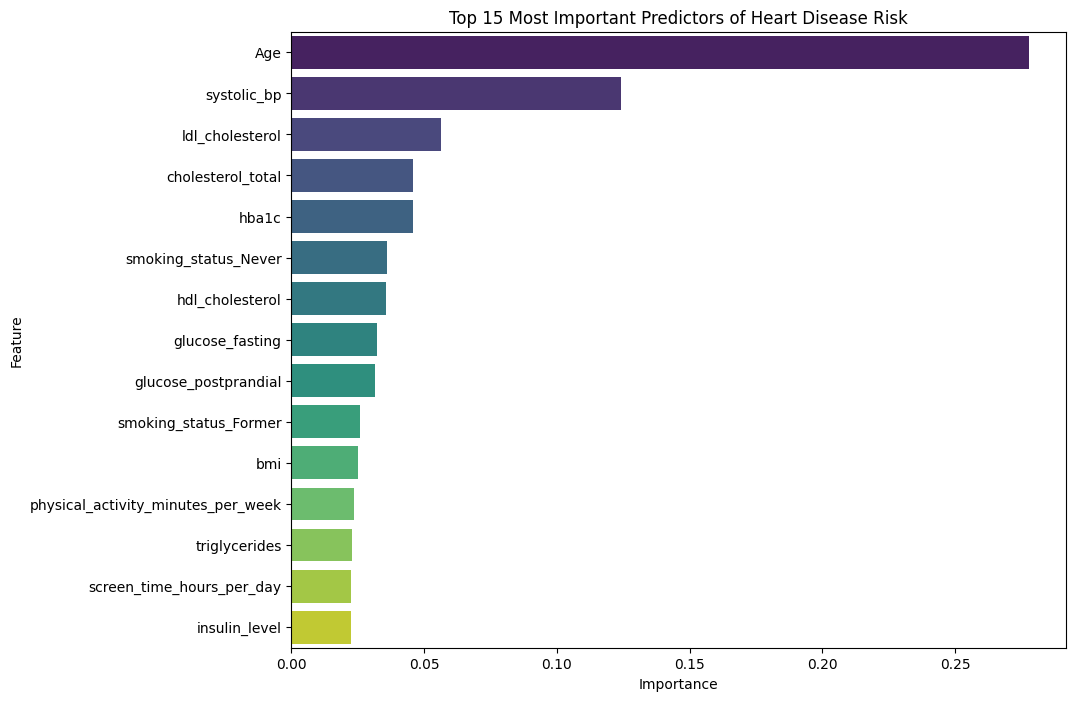

In [ ]:
# Analyze Feature Importance
importances = rf_model.feature_importances_
feature_names = X_encoded.columns
feat_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances}).sort_values(by='Importance', ascending=False)

# Plot the top 15 features
plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=feat_importance_df.head(15), palette='viridis')
plt.title('Top 15 Most Important Predictors of Heart Disease Risk')
plt.show()

## **Step 7: Predict the Risk for a New Person**
We enter the details of one person, apply the same one-hot encoding used in training, align the columns with the training features and let the Random Forest predict the risk group and the class probabilities. These probabilities are the model's estimates on this dataset and do not represent medical certainty.


In [ ]:
for col in X.select_dtypes(include='object').columns:
    print(col, '->', sorted(X[col].unique()))

gender -> ['Female', 'Male', 'Other']
ethnicity -> ['Asian', 'Black', 'Hispanic', 'Other', 'White']
education_level -> ['Graduate', 'Highschool', 'No formal', 'Postgraduate']
income_level -> ['High', 'Low', 'Lower-Middle', 'Middle', 'Upper-Middle']
employment_status -> ['Employed', 'Retired', 'Student', 'Unemployed']
smoking_status -> ['Current', 'Former', 'Never']


In [ ]:
# ---------- Predict for your own input ----------
new_person = {
    'Age': 45,
    'gender': 'Male',
    'ethnicity': 'Asian',
    'education_level': 'Graduate',
    'income_level': 'Middle',
    'employment_status': 'Employed',
    'smoking_status': 'Never',
    'alcohol_consumption_per_week': 1,
    'physical_activity_minutes_per_week': 150,
    'diet_score': 6.5,
    'sleep_hours_per_day': 7.0,
    'screen_time_hours_per_day': 5.0,
    'family_history_diabetes': 0,      # 0 = No, 1 = Yes
    'hypertension_history': 0,
    'cardiovascular_history': 0,
    'bmi': 24.5,
    'waist_to_hip_ratio': 0.88,
    'systolic_bp': 125,
    'diastolic_bp': 80,
    'heart_rate': 72,
    'cholesterol_total': 190,
    'hdl_cholesterol': 50,
    'ldl_cholesterol': 115,
    'triglycerides': 140,
    'glucose_fasting': 95,
    'glucose_postprandial': 140,
    'insulin_level': 8.0,
    'hba1c': 5.6,
}

# Catch spelling mistakes in categorical values
for col in X.select_dtypes(include='object').columns:
    assert new_person[col] in X[col].unique(), f"Invalid value for {col}: {new_person[col]}"

# Same column order as training
new_df = pd.DataFrame([new_person])[X.columns]

# One-hot encode, then match the exact training columns
new_encoded = pd.get_dummies(new_df)
new_encoded = new_encoded.reindex(columns=X_encoded.columns, fill_value=0)

# Predict
pred = rf_model.predict(new_encoded)[0]
probs = rf_model.predict_proba(new_encoded)[0]

print("Predicted Heart Disease Risk Group:", pred)
print("\nConfidence:")
for cls, p in zip(rf_model.classes_, probs):
    print(f"  {cls}: {p*100:.1f}%")

Predicted Heart Disease Risk Group: Low

Confidence:
  High: 3.0%
  Low: 49.0%
  Medium: 48.0%
